In [1]:

# STEP 1: Upload and extract the fruit dataset ZIP file

from google.colab import files
import zipfile
import os

# Upload your ZIP file from your computer
uploaded = files.upload()

# Get the uploaded ZIP filename
zip_filename = next(iter(uploaded))

# Create a folder for the dataset
extract_path = "/content/fruit_dataset"
os.makedirs(extract_path, exist_ok=True)

# Extract all files from the ZIP
with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset uploaded and extracted successfully!")
print("Dataset location:", extract_path)


Saving Fruits.zip to Fruits.zip
Dataset uploaded and extracted successfully!
Dataset location: /content/fruit_dataset


In [2]:

# STEP 2: Inspect dataset folders and count images

from pathlib import Path

dataset_path = Path("/content/fruit_dataset")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("DATASET FOLDER STRUCTURE\n")

for folder in sorted(dataset_path.rglob("*")):
    if folder.is_dir():
        images = [
            file for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() in image_extensions
        ]

        if images:
            print(f"{folder.name}: {len(images)} images")

print("\nTotal image files:",
      sum(1 for file in dataset_path.rglob("*")
          if file.is_file() and file.suffix.lower() in image_extensions))


DATASET FOLDER STRUCTURE

Apple__Healthy: 578 images
Apple__Rotten: 453 images
Banana__Healthy: 581 images
Banana__Rotten: 537 images
Orange__Healthy: 490 images
Orange__Rotten: 313 images

Total image files: 2952


In [7]:

# STEP 3B: Split the fruit dataset into training,
# validation, and testing folders

import os
import shutil
import random
from pathlib import Path
from sklearn.model_selection import train_test_split

random.seed(42)

# Original dataset location
source_path = Path("/content/fruit_dataset")

# Prepared dataset location
output_path = Path("/content/fruit_prepared")

# Actual folder names from your ZIP file
categories = [
    "Apple__Healthy",
    "Apple__Rotten",
    "Banana__Healthy",
    "Banana__Rotten",
    "Orange__Healthy",
    "Orange__Rotten"
]

# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Remove an earlier incomplete output, if present
if output_path.exists():
    shutil.rmtree(output_path)

output_path.mkdir(parents=True, exist_ok=True)

total_images = 0

for category in categories:

    category_folder = source_path / category

    if not category_folder.is_dir():
        raise FileNotFoundError(
            f"Folder not found: {category_folder}"
        )

    # Collect all images
    images = [
        file for file in category_folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    if len(images) < 3:
        raise ValueError(f"Not enough images in {category}")

    # 70% training, 30% temporary
    train_images, temporary_images = train_test_split(
        images,
        test_size=0.30,
        random_state=42
    )

    # Divide the remaining 30% equally
    val_images, test_images = train_test_split(
        temporary_images,
        test_size=0.50,
        random_state=42
    )

    # Create folders and copy images
    for split_name, split_images in [
        ("train", train_images),
        ("validation", val_images),
        ("test", test_images)
    ]:

        destination = output_path / split_name / category
        destination.mkdir(parents=True, exist_ok=True)

        for index, image_file in enumerate(split_images):
            new_name = (
                f"{category}_{index}{image_file.suffix.lower()}"
            )

            shutil.copy2(
                image_file,
                destination / new_name
            )

    total_images += len(images)

    print(
        f"{category}: "
        f"Train={len(train_images)}, "
        f"Validation={len(val_images)}, "
        f"Test={len(test_images)}"
    )

print("\nDataset splitting completed!")
print("Total images processed:", total_images)
print("Prepared dataset:", output_path)


Apple__Healthy: Train=404, Validation=87, Test=87
Apple__Rotten: Train=317, Validation=68, Test=68
Banana__Healthy: Train=406, Validation=87, Test=88
Banana__Rotten: Train=375, Validation=81, Test=81
Orange__Healthy: Train=343, Validation=73, Test=74
Orange__Rotten: Train=219, Validation=47, Test=47

Dataset splitting completed!
Total images processed: 2952
Prepared dataset: /content/fruit_prepared


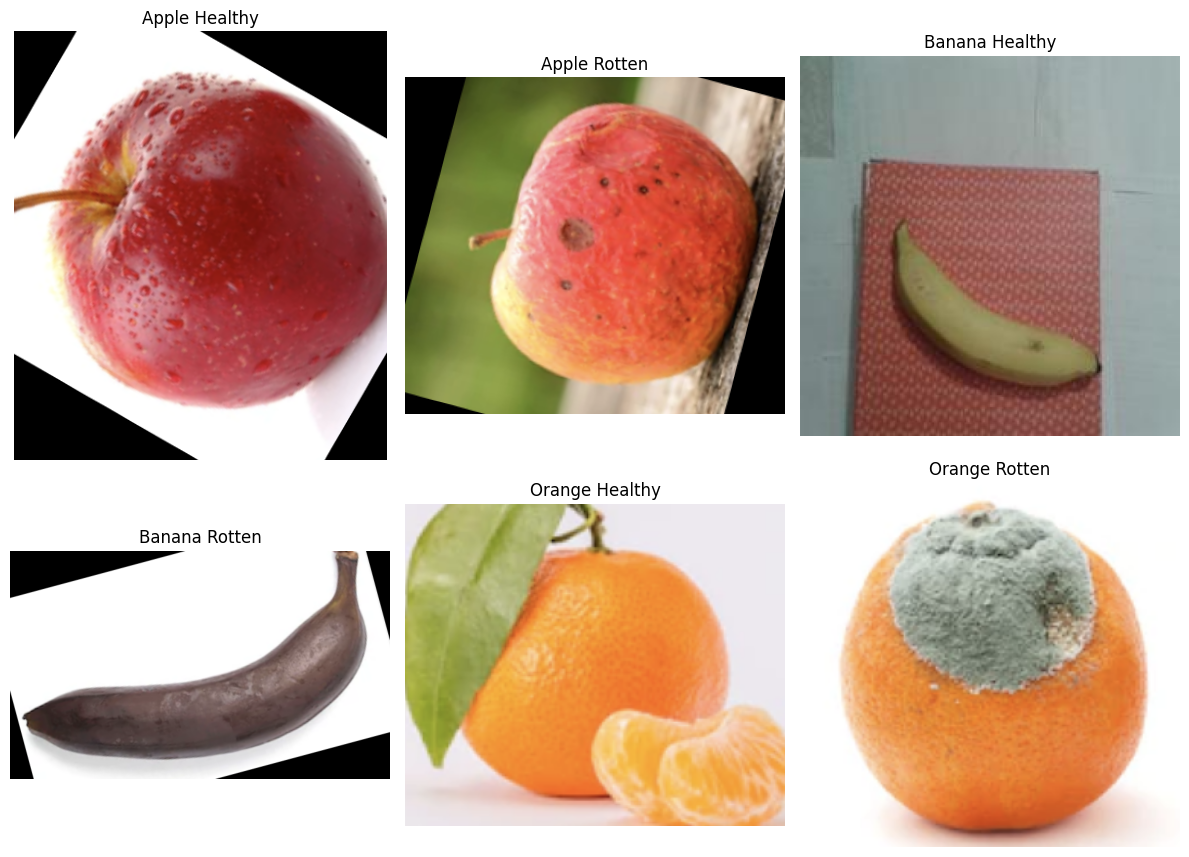

In [8]:

# STEP 4: Visual inspection of fruit images

import matplotlib.pyplot as plt
import random
from pathlib import Path
from PIL import Image

dataset_path = Path("/content/fruit_prepared/train")

categories = [
    "Apple__Healthy",
    "Apple__Rotten",
    "Banana__Healthy",
    "Banana__Rotten",
    "Orange__Healthy",
    "Orange__Rotten"
]

plt.figure(figsize=(12, 9))

for index, category in enumerate(categories):

    folder = dataset_path / category

    images = [
        file for file in folder.iterdir()
        if file.suffix.lower() in
        [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ]

    # Select one random image
    image_path = random.choice(images)

    # Open and display image
    image = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, index + 1)
    plt.imshow(image)
    plt.title(category.replace("__", " "))
    plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:

# STEP 5: Image preprocessing and dataset loading

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image settings
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16

# Dataset paths
train_path = "/content/fruit_prepared/train"
validation_path = "/content/fruit_prepared/validation"
test_path = "/content/fruit_prepared/test"

# MobileNetV2 preprocessing
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

validation_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

# Load training images
train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

# Load validation images
validation_data = validation_datagen.flow_from_directory(
    validation_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# Load testing images
test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# Display dataset information
print("\nDataset loading completed!")

print("Training images:", train_data.samples)
print("Validation images:", validation_data.samples)
print("Testing images:", test_data.samples)

print("\nClass labels:")
print(train_data.class_indices)


Found 2064 images belonging to 6 classes.
Found 443 images belonging to 6 classes.
Found 445 images belonging to 6 classes.

Dataset loading completed!
Training images: 2064
Validation images: 443
Testing images: 445

Class labels:
{'Apple__Healthy': 0, 'Apple__Rotten': 1, 'Banana__Healthy': 2, 'Banana__Rotten': 3, 'Orange__Healthy': 4, 'Orange__Rotten': 5}


In [10]:

# STEP 6: Build MobileNetV2 transfer learning model

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model

# Number of fruit categories
NUM_CLASSES = 6

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)

# Six-class output layer
output = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Create final model
model = Model(
    inputs=base_model.input,
    outputs=output
)

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:

# STEP 6A: Check MobileNetV2 model parameters

print("MODEL PARAMETER INFORMATION")
print("-" * 40)

print("Total Parameters:", model.count_params())

print(
    "Trainable Parameters:",
    sum(
        tf.keras.backend.count_params(weight)
        for weight in model.trainable_weights
    )
)

print(
    "Non-Trainable Parameters:",
    sum(
        tf.keras.backend.count_params(weight)
        for weight in model.non_trainable_weights
    )
)

print("-" * 40)
print("Model output shape:", model.output_shape)


MODEL PARAMETER INFORMATION
----------------------------------------
Total Parameters: 2265670
Trainable Parameters: 7686
Non-Trainable Parameters: 2257984
----------------------------------------
Model output shape: (None, 6)


In [15]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Training callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.00001
)

checkpoint = ModelCheckpoint(
    "/content/best_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True
)

# Train the model
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=10,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

print("MobileNetV2 training completed!")

Epoch 1/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 205s 2s/step - accuracy: 0.8675 - loss: 0.4051 - val_accuracy: 0.9503 - val_loss: 0.1767 - learning_rate: 0.0010
Epoch 2/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 179s 1s/step - accuracy: 0.9554 - loss: 0.1682 - val_accuracy: 0.9571 - val_loss: 0.1180 - learning_rate: 0.0010
Epoch 3/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 182s 1s/step - accuracy: 0.9617 - loss: 0.1223 - val_accuracy: 0.9729 - val_loss: 0.0894 - learning_rate: 0.0010
Epoch 4/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 180s 1s/step - accuracy: 0.9723 - loss: 0.0977 - val_accuracy: 0.9797 - val_loss: 0.0737 - learning_rate: 0.0010
Epoch 5/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 181s 1s/step - accuracy: 0.9757 - loss: 0.0824 - val_accuracy: 0.9819 - val_loss: 0.0647 - learning_rate: 0.0010
Epoch 6/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 180s 1s/step - accuracy: 0.9816 - loss: 0.0655 - val_accuracy: 0.9819 - val_loss: 0.0646 - learning_rate: 0.0010
Epoch 7/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 181s 1s/step - accuracy: 0.9884 - loss: 0.

In [13]:
from pathlib import Path
from PIL import Image

dataset_path = Path("/content/fruit_prepared")

splits = ["train", "validation", "test"]

valid_extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

corrupted_images = []

for split in splits:
    split_path = dataset_path / split

    for image_path in split_path.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in valid_extensions:
            try:
                with Image.open(image_path) as img:
                    img.verify()

            except Exception as error:
                corrupted_images.append(image_path)
                print("Problem image:", image_path)

print("\nTotal corrupted images found:", len(corrupted_images))

# Remove only corrupted images from the prepared dataset
for image_path in corrupted_images:
    image_path.unlink()

print("\nCorrupted images removed successfully.")

Problem image: /content/fruit_prepared/train/Banana__Rotten/Banana__Rotten_366.png
Problem image: /content/fruit_prepared/train/Banana__Healthy/Banana__Healthy_122.png
Problem image: /content/fruit_prepared/train/Orange__Healthy/Orange__Healthy_324.png

Total corrupted images found: 3

Corrupted images removed successfully.


In [14]:
train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

validation_data = validation_datagen.flow_from_directory(
    validation_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 2061 images belonging to 6 classes.
Found 443 images belonging to 6 classes.
Found 445 images belonging to 6 classes.


In [16]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=10,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

print("MobileNetV2 training completed!")

Epoch 1/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 179s 1s/step - accuracy: 0.9898 - loss: 0.0388 - val_accuracy: 0.9887 - val_loss: 0.0399 - learning_rate: 0.0010
Epoch 2/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 180s 1s/step - accuracy: 0.9908 - loss: 0.0375 - val_accuracy: 0.9865 - val_loss: 0.0402 - learning_rate: 0.0010
Epoch 3/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.9918 - loss: 0.0343 - val_accuracy: 0.9865 - val_loss: 0.0368 - learning_rate: 0.0010
Epoch 4/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 179s 1s/step - accuracy: 0.9937 - loss: 0.0303 - val_accuracy: 0.9910 - val_loss: 0.0370 - learning_rate: 0.0010
Epoch 5/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.9927 - loss: 0.0329 - val_accuracy: 0.9910 - val_loss: 0.0353 - learning_rate: 0.0010
Epoch 6/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.9913 - loss: 0.0312 - val_accuracy: 0.9910 - val_loss: 0.0373 - learning_rate: 0.0010
Epoch 7/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.9932 - loss: 0.

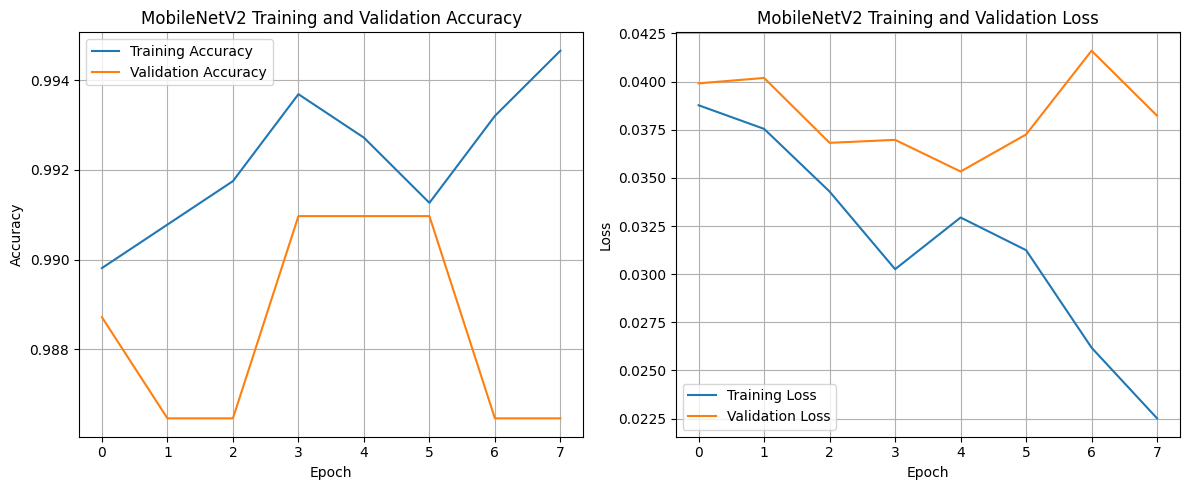

In [17]:
import matplotlib.pyplot as plt

# Create accuracy and loss graphs
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import classification_report
import numpy as np

# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(test_data)

print("\nMOBILENETV2 TEST RESULTS")
print("------------------------------")
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

# Generate predictions
predictions = model.predict(test_data)

predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_data.classes

# Get class names
class_names = list(test_data.class_indices.keys())

# Classification report
print("\nCLASSIFICATION REPORT")
print("------------------------------")

print(classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names,
    digits=4
))

28/28 ━━━━━━━━━━━━━━━━━━━━ 31s 995ms/step - accuracy: 0.9843 - loss: 0.0579

MOBILENETV2 TEST RESULTS
------------------------------
Test Accuracy: 98.43 %
Test Loss: 0.0579
28/28 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step   

CLASSIFICATION REPORT
------------------------------
                 precision    recall  f1-score   support

 Apple__Healthy     0.9556    0.9885    0.9718        87
  Apple__Rotten     1.0000    0.9559    0.9774        68
Banana__Healthy     1.0000    1.0000    1.0000        88
 Banana__Rotten     1.0000    1.0000    1.0000        81
Orange__Healthy     0.9861    0.9595    0.9726        74
 Orange__Rotten     0.9592    1.0000    0.9792        47

       accuracy                         0.9843       445
      macro avg     0.9835    0.9840    0.9835       445
   weighted avg     0.9847    0.9843    0.9843       445



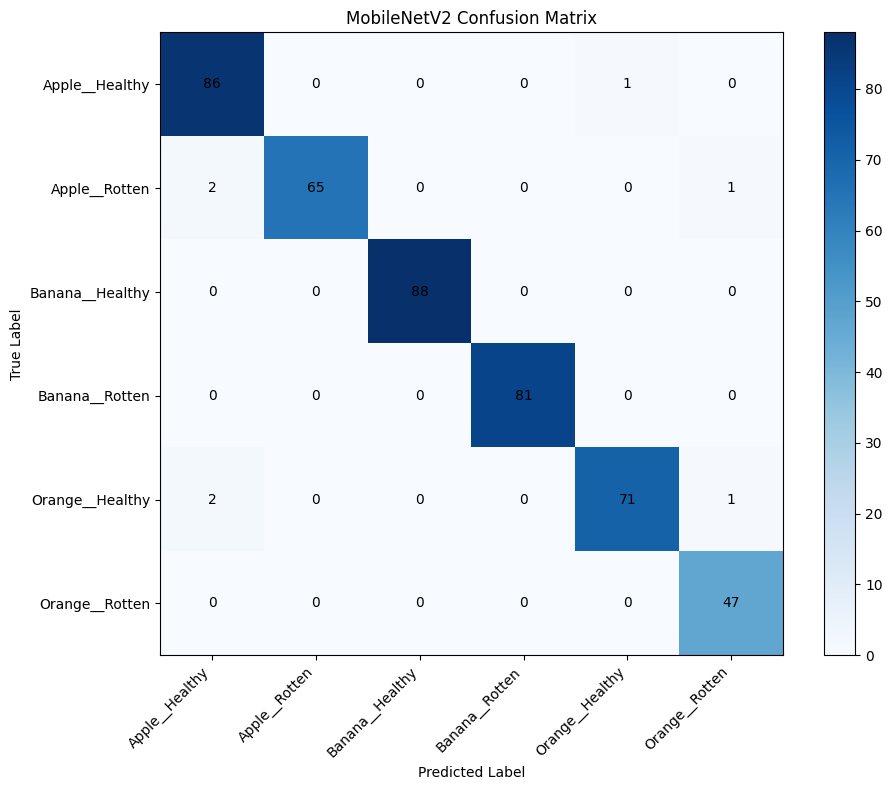

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

# Generate confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

# Plot confusion matrix
plt.figure(figsize=(10, 8))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("MobileNetV2 Confusion Matrix")
plt.colorbar()

class_names = list(test_data.class_indices.keys())

tick_marks = np.arange(len(class_names))

plt.xticks(tick_marks, class_names, rotation=45, ha="right")
plt.yticks(tick_marks, class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Display numbers inside the matrix
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()

In [20]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ResNet50 image preprocessing
resnet_train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.resnet50.preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

resnet_validation_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.resnet50.preprocess_input
)

resnet_test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.resnet50.preprocess_input
)

# Training images
resnet_train_data = resnet_train_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

# Validation images
resnet_validation_data = resnet_validation_datagen.flow_from_directory(
    validation_path,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=False
)

# Testing images
resnet_test_data = resnet_test_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=False
)

print("ResNet50 data preparation completed!")

Found 2061 images belonging to 6 classes.
Found 443 images belonging to 6 classes.
Found 445 images belonging to 6 classes.
ResNet50 data preparation completed!


In [21]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# Number of fruit categories
NUM_CLASSES = 6

# Load pretrained ResNet50
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
resnet_base.trainable = False

# Add classification layers
x = resnet_base.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)

output = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Build ResNet50 model
resnet_model = Model(
    inputs=resnet_base.input,
    outputs=output
)

# Compile model
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model summary
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,600,006 (90.03 MB)

 Trainable params: 12,294 (48.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [22]:
print("RESNET50 MODEL INFORMATION")
print("-" * 40)

print("Total Parameters:", resnet_model.count_params())

print(
    "Trainable Parameters:",
    sum(tf.keras.backend.count_params(w)
        for w in resnet_model.trainable_weights)
)

print(
    "Non-Trainable Parameters:",
    sum(tf.keras.backend.count_params(w)
        for w in resnet_model.non_trainable_weights)
)

print("Model Output Shape:", resnet_model.output_shape)

RESNET50 MODEL INFORMATION
----------------------------------------
Total Parameters: 23600006
Trainable Parameters: 12294
Non-Trainable Parameters: 23587712
Model Output Shape: (None, 6)


In [23]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# ResNet50 training callbacks
resnet_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

resnet_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.00001
)

resnet_checkpoint = ModelCheckpoint(
    "/content/best_resnet50.keras",
    monitor="val_loss",
    save_best_only=True
)

# Train ResNet50
resnet_history = resnet_model.fit(
    resnet_train_data,
    validation_data=resnet_validation_data,
    epochs=10,
    callbacks=[
        resnet_early_stop,
        resnet_reduce_lr,
        resnet_checkpoint
    ]
)

print("ResNet50 training completed!")

Epoch 1/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 599s 5s/step - accuracy: 0.8447 - loss: 0.4694 - val_accuracy: 0.9707 - val_loss: 0.1105 - learning_rate: 0.0010
Epoch 2/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 583s 5s/step - accuracy: 0.9641 - loss: 0.1130 - val_accuracy: 0.9819 - val_loss: 0.0823 - learning_rate: 0.0010
Epoch 3/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 578s 4s/step - accuracy: 0.9714 - loss: 0.0834 - val_accuracy: 0.9819 - val_loss: 0.0597 - learning_rate: 0.0010
Epoch 4/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 579s 4s/step - accuracy: 0.9835 - loss: 0.0547 - val_accuracy: 0.9865 - val_loss: 0.0512 - learning_rate: 0.0010
Epoch 5/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 579s 4s/step - accuracy: 0.9879 - loss: 0.0491 - val_accuracy: 0.9887 - val_loss: 0.0461 - learning_rate: 0.0010
Epoch 6/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 580s 5s/step - accuracy: 0.9918 - loss: 0.0375 - val_accuracy: 0.9910 - val_loss: 0.0427 - learning_rate: 0.0010
Epoch 7/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 579s 4s/step - accuracy: 0.9956 - loss: 0.

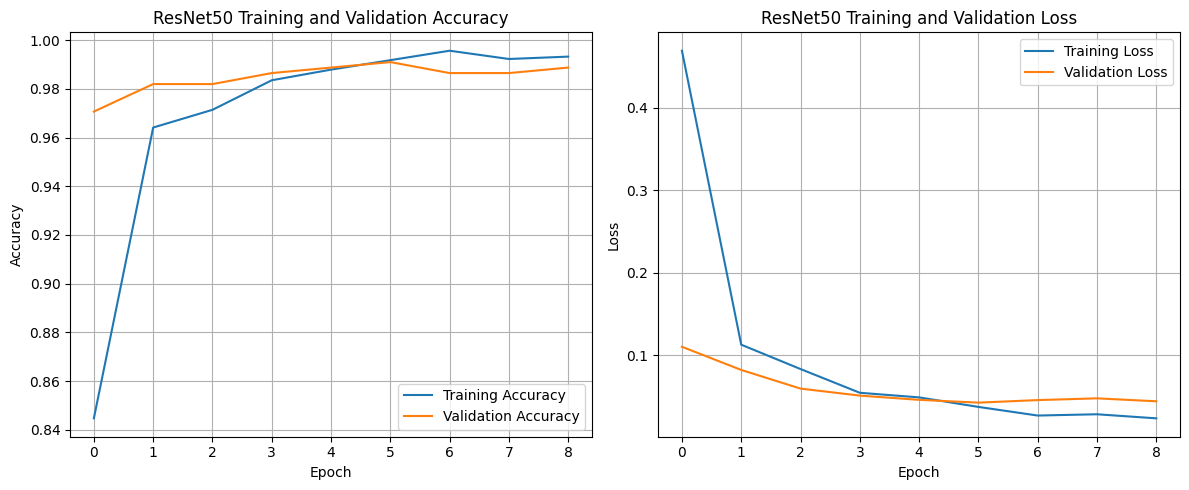

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(resnet_history.history["accuracy"], label="Training Accuracy")
plt.plot(resnet_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ResNet50 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(resnet_history.history["loss"], label="Training Loss")
plt.plot(resnet_history.history["val_loss"], label="Validation Loss")
plt.title("ResNet50 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [25]:
import numpy as np
from sklearn.metrics import classification_report

# Evaluate ResNet50
resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    resnet_test_data,
    verbose=1
)

print("\nRESNET50 TEST RESULTS")
print("------------------------------")
print("Test Accuracy:", round(resnet_test_accuracy * 100, 2), "%")
print("Test Loss:", round(resnet_test_loss, 4))

# Generate predictions
resnet_predictions = resnet_model.predict(
    resnet_test_data,
    verbose=1
)

resnet_predicted_classes = np.argmax(resnet_predictions, axis=1)
resnet_true_classes = resnet_test_data.classes

# Classification report
class_names = list(resnet_test_data.class_indices.keys())

print("\nCLASSIFICATION REPORT")
print("------------------------------")

print(classification_report(
    resnet_true_classes,
    resnet_predicted_classes,
    target_names=class_names,
    digits=4
))

28/28 ━━━━━━━━━━━━━━━━━━━━ 101s 4s/step - accuracy: 0.9933 - loss: 0.0302

RESNET50 TEST RESULTS
------------------------------
Test Accuracy: 99.33 %
Test Loss: 0.0302
28/28 ━━━━━━━━━━━━━━━━━━━━ 103s 4s/step

CLASSIFICATION REPORT
------------------------------
                 precision    recall  f1-score   support

 Apple__Healthy     0.9886    1.0000    0.9943        87
  Apple__Rotten     1.0000    0.9853    0.9926        68
Banana__Healthy     1.0000    1.0000    1.0000        88
 Banana__Rotten     1.0000    1.0000    1.0000        81
Orange__Healthy     0.9865    0.9865    0.9865        74
 Orange__Rotten     0.9787    0.9787    0.9787        47

       accuracy                         0.9933       445
      macro avg     0.9923    0.9918    0.9920       445
   weighted avg     0.9933    0.9933    0.9933       445



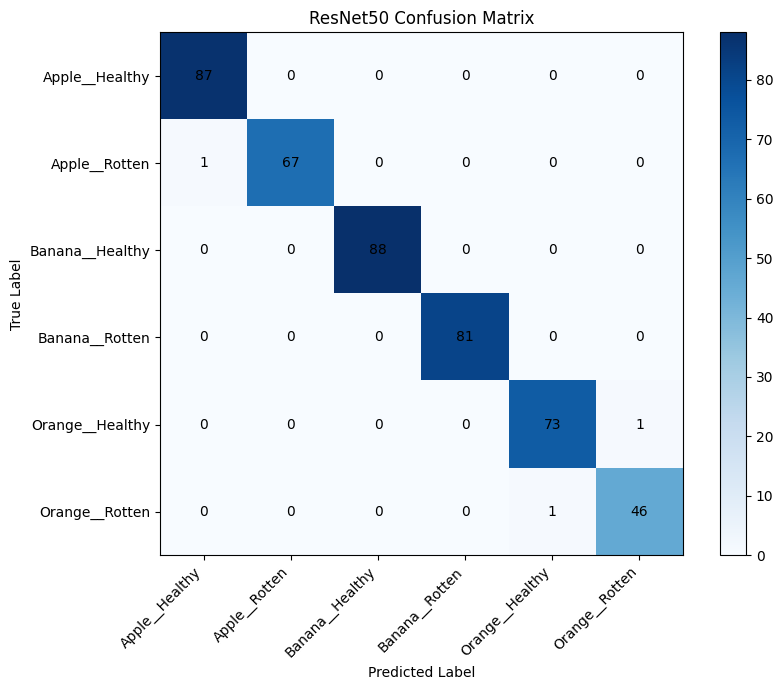

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

# Create confusion matrix
resnet_cm = confusion_matrix(
    resnet_true_classes,
    resnet_predicted_classes
)

# Plot confusion matrix
plt.figure(figsize=(9, 7))

plt.imshow(resnet_cm, cmap="Blues")
plt.title("ResNet50 Confusion Matrix")
plt.colorbar()

class_names = list(resnet_test_data.class_indices.keys())
tick_marks = np.arange(len(class_names))

plt.xticks(tick_marks, class_names, rotation=45, ha="right")
plt.yticks(tick_marks, class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Display values
for i in range(resnet_cm.shape[0]):
    for j in range(resnet_cm.shape[1]):
        plt.text(j, i, str(resnet_cm[i, j]),
                 ha="center", va="center", color="black")

plt.tight_layout()
plt.show()

In [27]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate MobileNetV2 metrics
mobilenet_results = {
    "Model": "MobileNetV2",
    "Accuracy": accuracy_score(true_classes, predicted_classes),
    "Precision": precision_score(
        true_classes, predicted_classes, average="weighted"
    ),
    "Recall": recall_score(
        true_classes, predicted_classes, average="weighted"
    ),
    "F1-Score": f1_score(
        true_classes, predicted_classes, average="weighted"
    )
}

# Calculate ResNet50 metrics
resnet_results = {
    "Model": "ResNet50",
    "Accuracy": accuracy_score(
        resnet_true_classes, resnet_predicted_classes
    ),
    "Precision": precision_score(
        resnet_true_classes, resnet_predicted_classes,
        average="weighted"
    ),
    "Recall": recall_score(
        resnet_true_classes, resnet_predicted_classes,
        average="weighted"
    ),
    "F1-Score": f1_score(
        resnet_true_classes, resnet_predicted_classes,
        average="weighted"
    )
}

# Create comparison table
comparison_df = pd.DataFrame([
    mobilenet_results,
    resnet_results
])

# Convert scores to percentages
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
comparison_df[metrics] = comparison_df[metrics] * 100

print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(comparison_df.round(2))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,MobileNetV2,98.43,98.47,98.43,98.43
1,ResNet50,99.33,99.33,99.33,99.33


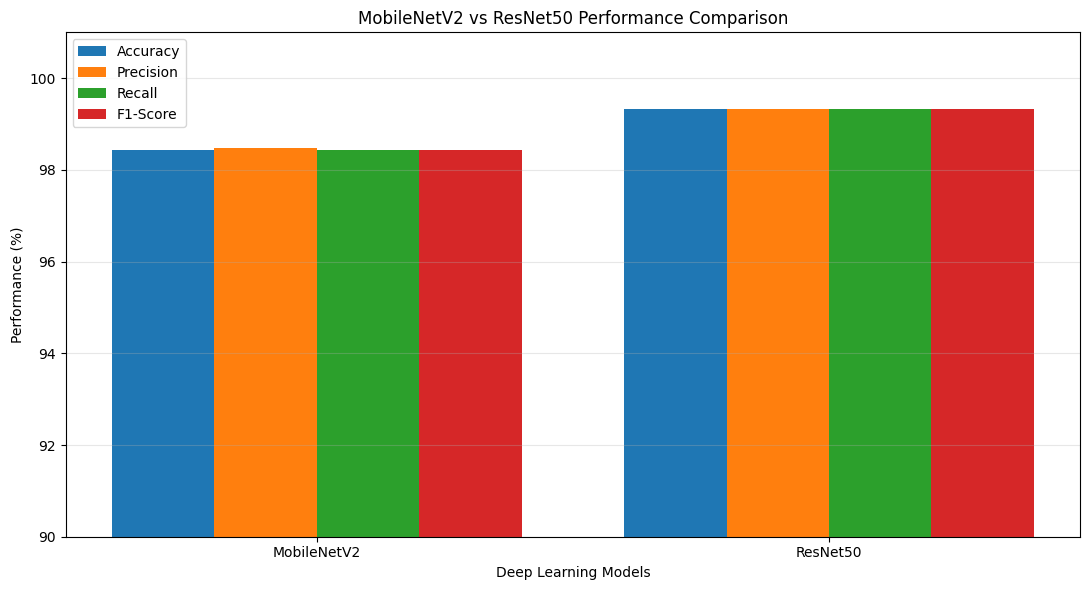

In [28]:
import matplotlib.pyplot as plt
import numpy as np

models = ["MobileNetV2", "ResNet50"]

accuracy = comparison_df["Accuracy"].values
precision = comparison_df["Precision"].values
recall = comparison_df["Recall"].values
f1 = comparison_df["F1-Score"].values

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(11, 6))

plt.bar(x - 1.5*width, accuracy, width, label="Accuracy")
plt.bar(x - 0.5*width, precision, width, label="Precision")
plt.bar(x + 0.5*width, recall, width, label="Recall")
plt.bar(x + 1.5*width, f1, width, label="F1-Score")

plt.title("MobileNetV2 vs ResNet50 Performance Comparison")
plt.xlabel("Deep Learning Models")
plt.ylabel("Performance (%)")

plt.xticks(x, models)
plt.ylim(90, 101)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [29]:
# Save MobileNetV2
model.save("/content/MobileNetV2_Final.keras")

# Save ResNet50
resnet_model.save("/content/ResNet50_Final.keras")

print("Both models saved successfully!")

Both models saved successfully!


In [30]:
from google.colab import files

files.download("/content/MobileNetV2_Final.keras")
files.download("/content/ResNet50_Final.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image settings
SMALL_IMAGE_SIZE = (160, 160)
SMALL_BATCH_SIZE = 16

# Data augmentation
small_train_datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

small_validation_datagen = ImageDataGenerator()
small_test_datagen = ImageDataGenerator()

# Training dataset
small_train_data = small_train_datagen.flow_from_directory(
    train_path,
    target_size=SMALL_IMAGE_SIZE,
    batch_size=SMALL_BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

# Validation dataset
small_validation_data = small_validation_datagen.flow_from_directory(
    validation_path,
    target_size=SMALL_IMAGE_SIZE,
    batch_size=SMALL_BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# Testing dataset
small_test_data = small_test_datagen.flow_from_directory(
    test_path,
    target_size=SMALL_IMAGE_SIZE,
    batch_size=SMALL_BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("MobileNetV3Small dataset preparation completed!")

Found 2061 images belonging to 6 classes.
Found 443 images belonging to 6 classes.
Found 445 images belonging to 6 classes.
MobileNetV3Small dataset preparation completed!


In [32]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# Load lightweight pretrained model
small_base = MobileNetV3Small(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

# Freeze pretrained layers
small_base.trainable = False

# Add classification layers
x = small_base.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.2)(x)

output = Dense(6, activation="softmax")(x)

# Build final model
small_model = Model(
    inputs=small_base.input,
    outputs=output
)

# Compile model
small_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV3Small model created successfully!")
print("Total Parameters:", small_model.count_params())
print("Trainable Parameters:", sum(
    tf.keras.backend.count_params(w)
    for w in small_model.trainable_weights
))
print("Output Shape:", small_model.output_shape)

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV3Small model created successfully!
Total Parameters: 942582
Trainable Parameters: 3462
Output Shape: (None, 6)


In [33]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

small_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

small_checkpoint = ModelCheckpoint(
    "/content/best_mobilenetv3small.keras",
    monitor="val_loss",
    save_best_only=True
)

small_history = small_model.fit(
    small_train_data,
    validation_data=small_validation_data,
    epochs=5,
    callbacks=[
        small_early_stop,
        small_checkpoint
    ]
)

print("MobileNetV3Small training completed!")

Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 79s 548ms/step - accuracy: 0.7045 - loss: 0.8531 - val_accuracy: 0.9007 - val_loss: 0.3253
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 67s 513ms/step - accuracy: 0.9151 - loss: 0.2917 - val_accuracy: 0.9323 - val_loss: 0.2095
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 68s 523ms/step - accuracy: 0.9447 - loss: 0.2032 - val_accuracy: 0.9594 - val_loss: 0.1491
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 67s 518ms/step - accuracy: 0.9510 - loss: 0.1641 - val_accuracy: 0.9594 - val_loss: 0.1275
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 67s 521ms/step - accuracy: 0.9597 - loss: 0.1399 - val_accuracy: 0.9729 - val_loss: 0.1013
MobileNetV3Small training completed!


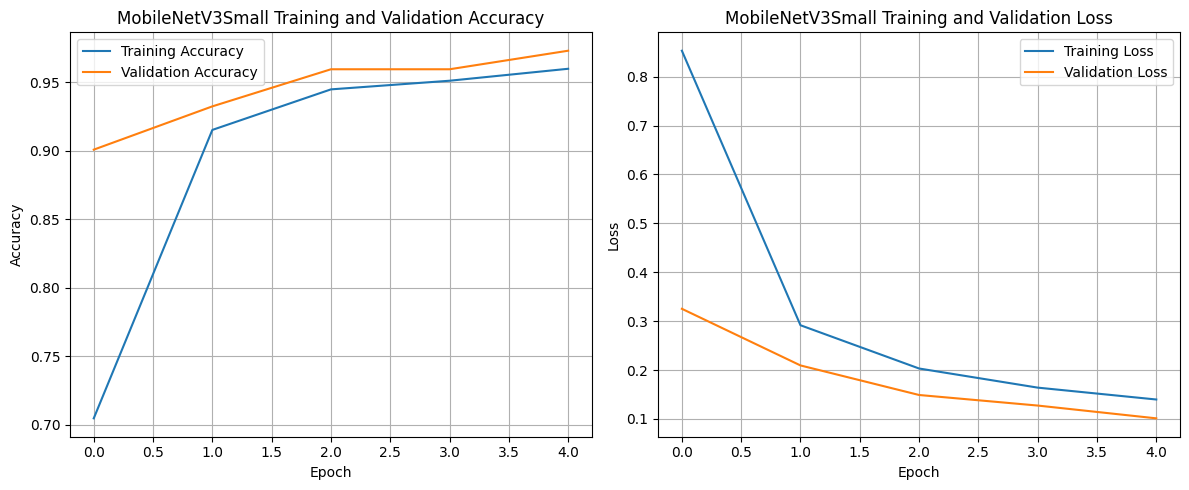

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(small_history.history["accuracy"], label="Training Accuracy")
plt.plot(small_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV3Small Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(small_history.history["loss"], label="Training Loss")
plt.plot(small_history.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV3Small Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(
    "/content/MobileNetV3Small_Training_Graphs.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [35]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
small_cm = confusion_matrix(
    small_true_classes,
    small_predicted_classes
)

# Plot
plt.figure(figsize=(9, 7))

display = ConfusionMatrixDisplay(
    confusion_matrix=small_cm,
    display_labels=small_class_names
)

display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("MobileNetV3Small Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/content/MobileNetV3Small_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'small_true_classes' is not defined

In [36]:
import numpy as np

# Generate predictions
small_predictions = small_model.predict(
    small_test_data,
    verbose=1
)

# Convert predictions into class labels
small_predicted_classes = np.argmax(
    small_predictions,
    axis=1
)

# Get actual test labels
small_true_classes = small_test_data.classes

# Get category names
small_class_names = list(
    small_test_data.class_indices.keys()
)

print("Predictions generated successfully!")
print("Total test images:", len(small_true_classes))
print("Predicted images:", len(small_predicted_classes))
print("Categories:", small_class_names)

28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 370ms/step
Predictions generated successfully!
Total test images: 445
Predicted images: 445
Categories: ['Apple__Healthy', 'Apple__Rotten', 'Banana__Healthy', 'Banana__Rotten', 'Orange__Healthy', 'Orange__Rotten']


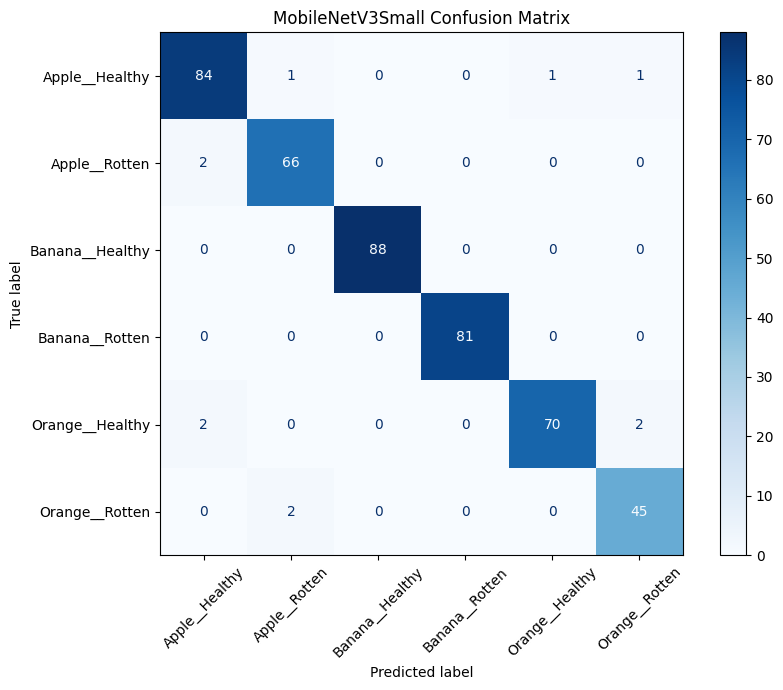

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

small_cm = confusion_matrix(
    small_true_classes,
    small_predicted_classes
)

fig, ax = plt.subplots(figsize=(9, 7))

display = ConfusionMatrixDisplay(
    confusion_matrix=small_cm,
    display_labels=small_class_names
)

display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

plt.title("MobileNetV3Small Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/content/MobileNetV3Small_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:


import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from IPython.display import display as show_table

model_results = {
    "MobileNetV2": (true_classes, predicted_classes),
    "ResNet50": (resnet_true_classes, resnet_predicted_classes),
    "MobileNetV3Small": (small_true_classes, small_predicted_classes)
}

comparison_results = []

for model_name, (y_true, y_pred) in model_results.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ) * 100,
        "F1-Score (%)": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ) * 100
    })

comparison_df = pd.DataFrame(comparison_results).round(2)

print("THREE-MODEL PERFORMANCE COMPARISON")
show_table(comparison_df.style.hide(axis="index"))


THREE-MODEL PERFORMANCE COMPARISON


Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
MobileNetV2,98.430000,98.470000,98.430000,98.430000
ResNet50,99.330000,99.330000,99.330000,99.330000
MobileNetV3Small,97.530000,97.550000,97.530000,97.530000


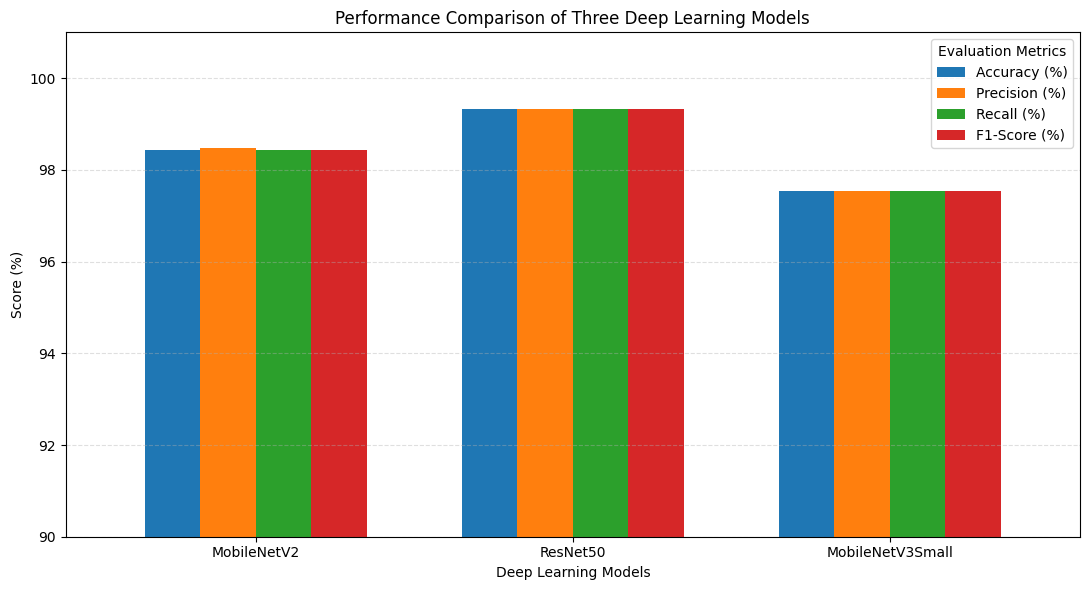

In [42]:

import matplotlib.pyplot as plt

metrics = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.7
)

plt.title("Performance Comparison of Three Deep Learning Models")
plt.ylabel("Score (%)")
plt.xlabel("Deep Learning Models")
plt.ylim(90, 101)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    "/content/Three_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [43]:
small_model.save("/content/MobileNetV3Small_Final.keras")

print("MobileNetV3Small model saved successfully!")

MobileNetV3Small model saved successfully!


In [44]:
import os

model_files = [
    "/content/MobileNetV2_Final.keras",
    "/content/ResNet50_Final.keras",
    "/content/MobileNetV3Small_Final.keras"
]

print("SAVED MODEL FILES")
print("-------------------------")

for file_path in model_files:
    if os.path.exists(file_path):
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"✓ {os.path.basename(file_path)} - {size_mb:.2f} MB")
    else:
        print(f"✗ Missing: {os.path.basename(file_path)}")

SAVED MODEL FILES
-------------------------
✓ MobileNetV2_Final.keras - 9.26 MB
✓ ResNet50_Final.keras - 90.74 MB
✓ MobileNetV3Small_Final.keras - 4.16 MB


In [45]:

import os
import zipfile

# Create ZIP file
zip_path = "/content/Fruit_Quality_Inspection_Results.zip"

# Files to include
files_to_save = [
    "/content/MobileNetV2_Final.keras",
    "/content/ResNet50_Final.keras",
    "/content/MobileNetV3Small_Final.keras",
    "/content/Three_Model_Comparison.png",
    "/content/MobileNetV3Small_Confusion_Matrix.png"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:

    for file_path in files_to_save:
        if os.path.exists(file_path):
            zipf.write(file_path, os.path.basename(file_path))
            print("Added:", os.path.basename(file_path))
        else:
            print("Not found:", os.path.basename(file_path))

print("\nZIP file created successfully!")
print("Location:", zip_path)


Added: MobileNetV2_Final.keras
Added: ResNet50_Final.keras
Added: MobileNetV3Small_Final.keras
Added: Three_Model_Comparison.png
Added: MobileNetV3Small_Confusion_Matrix.png

ZIP file created successfully!
Location: /content/Fruit_Quality_Inspection_Results.zip


In [47]:
from google.colab import files

files.download("/content/Fruit_Quality_Inspection_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

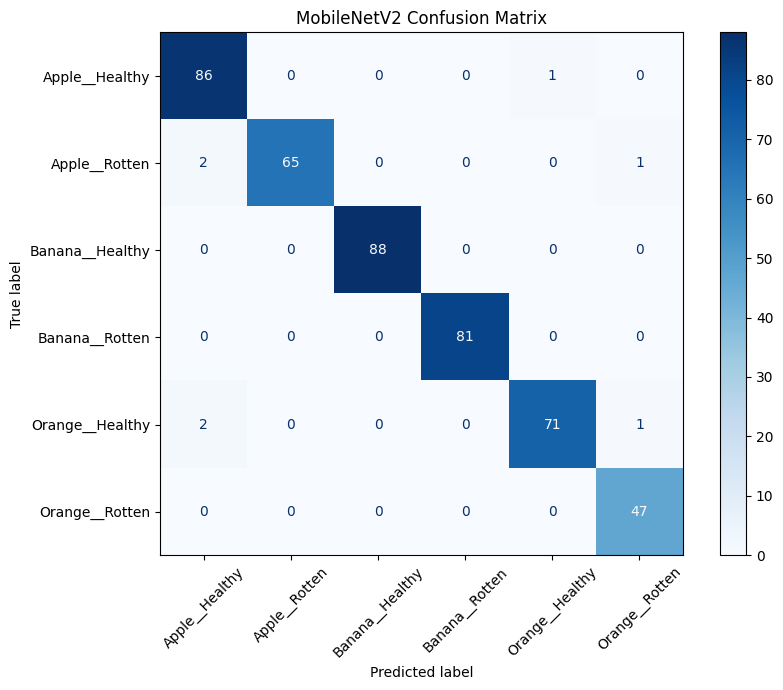

MobileNetV2 confusion matrix saved successfully!


In [48]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
mobilenet_cm = confusion_matrix(
    true_classes,
    predicted_classes
)

# Display confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=mobilenet_cm,
    display_labels=class_names
)

cm_display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()

# Save image
plt.savefig(
    "/content/MobileNetV2_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("MobileNetV2 confusion matrix saved successfully!")


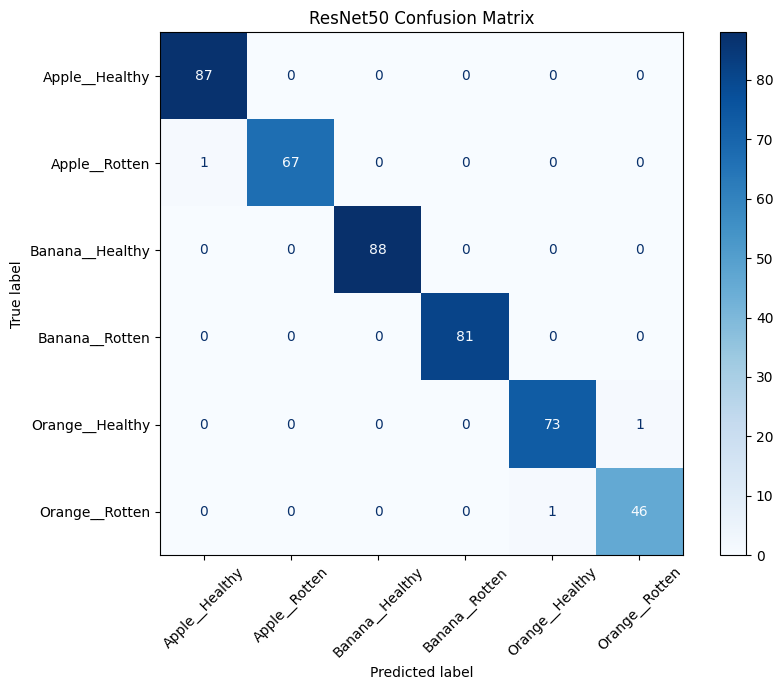

ResNet50 confusion matrix saved successfully!


In [49]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
resnet_cm = confusion_matrix(
    resnet_true_classes,
    resnet_predicted_classes
)

# Display confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=resnet_cm,
    display_labels=class_names
)

cm_display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

plt.title("ResNet50 Confusion Matrix")
plt.tight_layout()

# Save image
plt.savefig(
    "/content/ResNet50_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ResNet50 confusion matrix saved successfully!")


In [50]:

from sklearn.metrics import classification_report

# Generate reports
mobilenet_report = classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names,
    zero_division=0
)

resnet_report = classification_report(
    resnet_true_classes,
    resnet_predicted_classes,
    target_names=class_names,
    zero_division=0
)

small_report = classification_report(
    small_true_classes,
    small_predicted_classes,
    target_names=class_names,
    zero_division=0
)

# Display reports
print("========== MobileNetV2 ==========")
print(mobilenet_report)

print("\n========== ResNet50 ==========")
print(resnet_report)

print("\n========== MobileNetV3Small ==========")
print(small_report)


========== MobileNetV2 ==========
                 precision    recall  f1-score   support

 Apple__Healthy       0.96      0.99      0.97        87
  Apple__Rotten       1.00      0.96      0.98        68
Banana__Healthy       1.00      1.00      1.00        88
 Banana__Rotten       1.00      1.00      1.00        81
Orange__Healthy       0.99      0.96      0.97        74
 Orange__Rotten       0.96      1.00      0.98        47

       accuracy                           0.98       445
      macro avg       0.98      0.98      0.98       445
   weighted avg       0.98      0.98      0.98       445


========== ResNet50 ==========
                 precision    recall  f1-score   support

 Apple__Healthy       0.99      1.00      0.99        87
  Apple__Rotten       1.00      0.99      0.99        68
Banana__Healthy       1.00      1.00      1.00        88
 Banana__Rotten       1.00      1.00      1.00        81
Orange__Healthy       0.99      0.99      0.99        74
 Orange__Rotten   

In [51]:

reports = {
    "MobileNetV2_Classification_Report.txt": mobilenet_report,
    "ResNet50_Classification_Report.txt": resnet_report,
    "MobileNetV3Small_Classification_Report.txt": small_report
}

for filename, report in reports.items():
    with open("/content/" + filename, "w") as file:
        file.write(report)
    print("Saved:", filename)

print("\nAll classification reports saved successfully!")


Saved: MobileNetV2_Classification_Report.txt
Saved: ResNet50_Classification_Report.txt
Saved: MobileNetV3Small_Classification_Report.txt

All classification reports saved successfully!


In [52]:

import os
import zipfile

zip_path = "/content/Fruit_Quality_Inspection_Final_Results.zip"

files_to_save = [
    "/content/MobileNetV2_Final.keras",
    "/content/ResNet50_Final.keras",
    "/content/MobileNetV3Small_Final.keras",

    "/content/MobileNetV2_Confusion_Matrix.png",
    "/content/ResNet50_Confusion_Matrix.png",
    "/content/MobileNetV3Small_Confusion_Matrix.png",

    "/content/Three_Model_Comparison.png",

    "/content/MobileNetV2_Classification_Report.txt",
    "/content/ResNet50_Classification_Report.txt",
    "/content/MobileNetV3Small_Classification_Report.txt"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in files_to_save:
        if os.path.exists(file_path):
            zipf.write(file_path, os.path.basename(file_path))
            print("Added:", os.path.basename(file_path))
        else:
            print("Missing:", os.path.basename(file_path))

print("\nFinal project results ZIP created!")


Added: MobileNetV2_Final.keras
Added: ResNet50_Final.keras
Added: MobileNetV3Small_Final.keras
Added: MobileNetV2_Confusion_Matrix.png
Added: ResNet50_Confusion_Matrix.png
Added: MobileNetV3Small_Confusion_Matrix.png
Added: Three_Model_Comparison.png
Added: MobileNetV2_Classification_Report.txt
Added: ResNet50_Classification_Report.txt
Added: MobileNetV3Small_Classification_Report.txt

Final project results ZIP created!


In [53]:
from google.colab import files

files.download("/content/Fruit_Quality_Inspection_Final_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:

import os
import hashlib
from collections import defaultdict

dataset_path = "/content/fruit_prepared"

# Store image hashes and their locations
image_hashes = defaultdict(list)

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# Scan all three dataset folders
for split in ["train", "validation", "test"]:
    split_path = os.path.join(dataset_path, split)

    for root, dirs, files in os.walk(split_path):
        for filename in files:
            if filename.lower().endswith(valid_extensions):
                file_path = os.path.join(root, filename)

                with open(file_path, "rb") as image_file:
                    image_hash = hashlib.md5(
                        image_file.read()
                    ).hexdigest()

                image_hashes[image_hash].append({
                    "split": split,
                    "path": file_path
                })

# Find exact duplicates appearing across different splits
duplicate_groups = []

for image_hash, locations in image_hashes.items():
    splits = set(item["split"] for item in locations)

    if len(splits) > 1:
        duplicate_groups.append(locations)

print("DATASET DUPLICATE IMAGE CHECK")
print("--------------------------------")
print("Exact duplicate groups across splits:", len(duplicate_groups))

for number, group in enumerate(duplicate_groups, start=1):
    print(f"\nDuplicate group {number}:")
    for item in group:
        print(item["split"], ":", item["path"])

if len(duplicate_groups) == 0:
    print("\nNo exact duplicates found across train, validation, and test.")


DATASET DUPLICATE IMAGE CHECK
--------------------------------
Exact duplicate groups across splits: 0

No exact duplicates found across train, validation, and test.


In [56]:

import os

dataset_path = "/content/fruit_prepared"

splits = ["train", "validation", "test"]

print("FINAL DATASET DISTRIBUTION")
print("=" * 65)

for split in splits:
    print(f"\n{split.upper()} DATASET")

    split_path = os.path.join(dataset_path, split)
    total = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = sum(
                1 for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
            )

            print(f"{class_name}: {count}")
            total += count

    print("Total:", total)

print("\nDataset distribution check completed!")


FINAL DATASET DISTRIBUTION

TRAIN DATASET
Apple__Healthy: 404
Apple__Rotten: 317
Banana__Healthy: 405
Banana__Rotten: 374
Orange__Healthy: 342
Orange__Rotten: 219
Total: 2061

VALIDATION DATASET
Apple__Healthy: 87
Apple__Rotten: 68
Banana__Healthy: 87
Banana__Rotten: 81
Orange__Healthy: 73
Orange__Rotten: 47
Total: 443

TEST DATASET
Apple__Healthy: 87
Apple__Rotten: 68
Banana__Healthy: 88
Banana__Rotten: 81
Orange__Healthy: 74
Orange__Rotten: 47
Total: 445

Dataset distribution check completed!


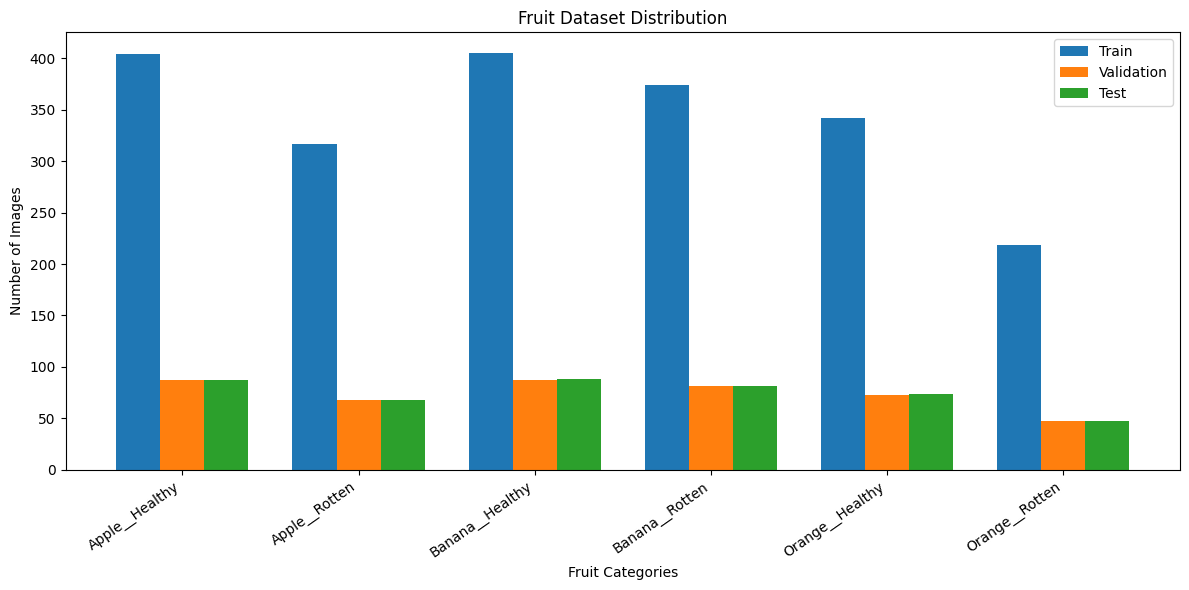

Dataset distribution graph saved successfully!


In [57]:

import matplotlib.pyplot as plt
import os

dataset_path = "/content/fruit_prepared"

splits = ["train", "validation", "test"]
class_names = sorted(os.listdir(os.path.join(dataset_path, "train")))

data = {}

for split in splits:
    split_path = os.path.join(dataset_path, split)
    counts = []

    for class_name in class_names:
        class_path = os.path.join(split_path, class_name)

        count = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        counts.append(count)

    data[split.capitalize()] = counts

x = range(len(class_names))
width = 0.25

plt.figure(figsize=(12, 6))

for i, (split, counts) in enumerate(data.items()):
    positions = [v + (i - 1) * width for v in x]
    plt.bar(positions, counts, width=width, label=split)

plt.title("Fruit Dataset Distribution")
plt.xlabel("Fruit Categories")
plt.ylabel("Number of Images")
plt.xticks(list(x), class_names, rotation=35, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/Dataset_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dataset distribution graph saved successfully!")


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image
from tensorflow.keras.applications.resnet50 import preprocess_input

# Load the trained ResNet50 model
fruit_model = tf.keras.models.load_model("/content/ResNet50_Final.keras")

class_names = [
    "Apple__Healthy", "Apple__Rotten",
    "Banana__Healthy", "Banana__Rotten",
    "Orange__Healthy", "Orange__Rotten"
]

# Preliminary confidence threshold (70%)
CONFIDENCE_THRESHOLD = 70

print("Upload an Apple, Banana, or Orange image:")
uploaded = files.upload()

for filename in uploaded.keys():

    image = Image.open(filename).convert("RGB")
    image_resized = image.resize((224, 224))

    image_array = np.array(image_resized)
    image_array = np.expand_dims(image_array, axis=0)
    image_array = preprocess_input(image_array.astype(np.float32))

    predictions = fruit_model.predict(image_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    confidence = float(predictions[0][predicted_index] * 100)

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Uploaded Image")
    plt.show()

    print("=" * 45)

    if confidence < CONFIDENCE_THRESHOLD:
        print("ERROR: Unsupported or uncertain image!")
        print("This image could not be confidently classified.")
        print("Please upload an Apple, Banana, or Orange image.")

    else:
        predicted_class = class_names[predicted_index]
        fruit_name, quality = predicted_class.split("__")

        print("FRUIT QUALITY CLASSIFICATION RESULT")
        print("Fruit Type:", fruit_name)
        print("Fruit Quality:", quality)
        print(f"Prediction Confidence: {confidence:.2f}%")

    print("=" * 45)


Upload an Apple, Banana, or Orange image:
